## Imports ##

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, multilabel_confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, TransformerMixin
from scipy.stats import chi2_contingency
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Load UCI Car Evaluation Dataset ##

In [2]:
# Load the UCI Car Evaluation dataset (id 19) from the local CSV submitted with this notebook.
# If the CSV is missing, download it once from the UCI repository and save it here.
from pathlib import Path

data_path = Path("car_evaluation.csv")
if data_path.exists():
    car_data = pd.read_csv(data_path, dtype=str)
else:
    car_evaluation = fetch_ucirepo(id=19)
    car_data = pd.concat([car_evaluation.data.features, car_evaluation.data.targets], axis=1)
    car_data.to_csv(data_path, index=False)

# data (as pandas dataframes)
X = car_data.drop(columns="class")
y = car_data[["class"]]

print(f"Loaded {data_path}: {X.shape[0]} rows, {X.shape[1]} features")
print("Features:", list(X.columns))

Loaded car_evaluation.csv: 1728 rows, 6 features
Features: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety']


## Identify Dataset Metadata & Visualisation ##

In [3]:
# Dataset summary and integrity audit against the UCI specification.
expected_features = ["buying", "maint", "doors", "persons", "lug_boot", "safety"]
expected_categories = {
    "buying": {"vhigh", "high", "med", "low"},
    "maint": {"vhigh", "high", "med", "low"},
    "doors": {"2", "3", "4", "5more"},
    "persons": {"2", "4", "more"},
    "lug_boot": {"small", "med", "big"},
    "safety": {"low", "med", "high"},
}
target_order = ["unacc", "acc", "good", "vgood"]
colors = {
    "unacc": "#C20303",
    "acc": "#FFC400",
    "good": "#59A14F",
    "vgood": "#2FF4A2",
}
target = y.squeeze()

metadata_summary = pd.DataFrame({
    "Data type": X.dtypes.astype(str),
    "Unique values": X.nunique(dropna=True),
    "Missing values": X.isna().sum(),
})
display(metadata_summary)

# Build one compact report covering missingness, schema, values, and label consistency.
audit = []
def add_check(check, status, details):
    audit.append({"Check": check, "Status": status, "Details": details})

add_check("Dataset size", "PASS" if len(X) == 1728 else "REVIEW", f"{len(X)} rows (UCI reference: 1728)")
add_check("Expected feature columns", "PASS" if list(X.columns) == expected_features else "REVIEW", f"Observed: {list(X.columns)}")
add_check("Categorical feature types", "PASS" if all(pd.api.types.is_string_dtype(dtype) or isinstance(dtype, pd.CategoricalDtype) for dtype in X.dtypes) else "REVIEW", ", ".join(f"{col}: {dtype}" for col, dtype in X.dtypes.items()))
add_check("Missing feature values", "PASS" if not X.isna().any().any() else "REVIEW", f"{int(X.isna().sum().sum())} missing cells")
add_check("Missing target values", "PASS" if not target.isna().any() else "REVIEW", f"{int(target.isna().sum())} missing labels")
add_check("Duplicate feature rows", "PASS" if not X.duplicated().any() else "REVIEW", f"{int(X.duplicated().sum())} duplicate rows")

for column, expected in expected_categories.items():
    if column not in X.columns:
        add_check(f"Values in {column}", "REVIEW", "Expected feature column is missing")
        continue
    observed = set(X[column].dropna().astype(str).unique())
    unexpected = sorted(observed - expected)
    absent = sorted(expected - observed)
    status = "REVIEW" if unexpected or absent else "PASS"
    add_check(f"Values in {column}", status, f"Unexpected: {unexpected}; documented but not observed: {absent}")

expected_target_labels = set(target_order)
observed_targets = set(target.dropna().astype(str).unique())
unexpected_targets = sorted(observed_targets - expected_target_labels)
absent_targets = sorted(expected_target_labels - observed_targets)
add_check("Target labels", "REVIEW" if unexpected_targets or absent_targets else "PASS", f"Unexpected: {unexpected_targets}; documented but not observed: {absent_targets}")

if set(expected_features).issubset(X.columns):
    rows_with_target = X[expected_features].reset_index(drop=True).copy()
    rows_with_target["target"] = target.reset_index(drop=True)
    labels_per_feature_row = rows_with_target.groupby(expected_features, dropna=False)["target"].nunique()
    conflicting_rows = int((labels_per_feature_row > 1).sum())
    add_check("Conflicting labels for identical feature rows", "PASS" if conflicting_rows == 0 else "REVIEW", f"{conflicting_rows} feature combinations have multiple labels")

constant_features = X.columns[X.nunique(dropna=False) <= 1].tolist()
add_check("Constant features", "PASS" if not constant_features else "REVIEW", f"{constant_features}")
display(pd.DataFrame(audit))

# Show the target distribution in the same explicit class order.
target_counts = target.value_counts().reindex(target_order, fill_value=0)
display(pd.DataFrame({"Count": target_counts, "Proportion": (target_counts / len(target)).round(3)}))

,Data type,Unique values,Missing values
buying,str,4,0
maint,str,4,0
doors,str,4,0
persons,str,3,0
lug_boot,str,3,0
safety,str,3,0


,Check,Status,Details
0,Dataset size,PASS,1728 rows (UCI reference: 1728)
1,Expected feature columns,PASS,"Observed: ['buying', 'maint', 'doors', 'person..."
2,Categorical feature types,PASS,"buying: str, maint: str, doors: str, persons: ..."
3,Missing feature values,PASS,0 missing cells
4,Missing target values,PASS,0 missing labels
5,Duplicate feature rows,PASS,0 duplicate rows
6,Values in buying,PASS,Unexpected: []; documented but not observed: []
7,Values in maint,PASS,Unexpected: []; documented but not observed: []
8,Values in doors,PASS,Unexpected: []; documented but not observed: []
9,Values in persons,PASS,Unexpected: []; documented but not observed: []


,Count,Proportion
class,,
unacc,1210,0.700
acc,384,0.222
good,69,0.040
vgood,65,0.038


In [4]:
# Hold out 40% for final testing before plotting target relationships or tuning models.
X_train, X_test, y_train, y_test = train_test_split(
    X, target, test_size=0.40, random_state=42, stratify=target
)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

Training rows: 1036 | Test rows: 692


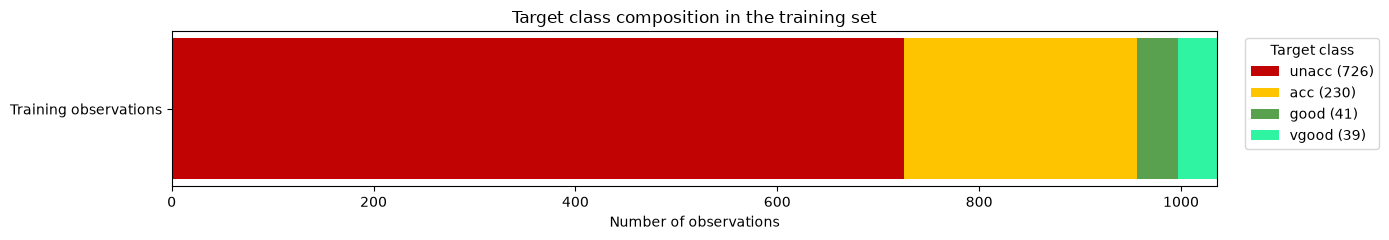

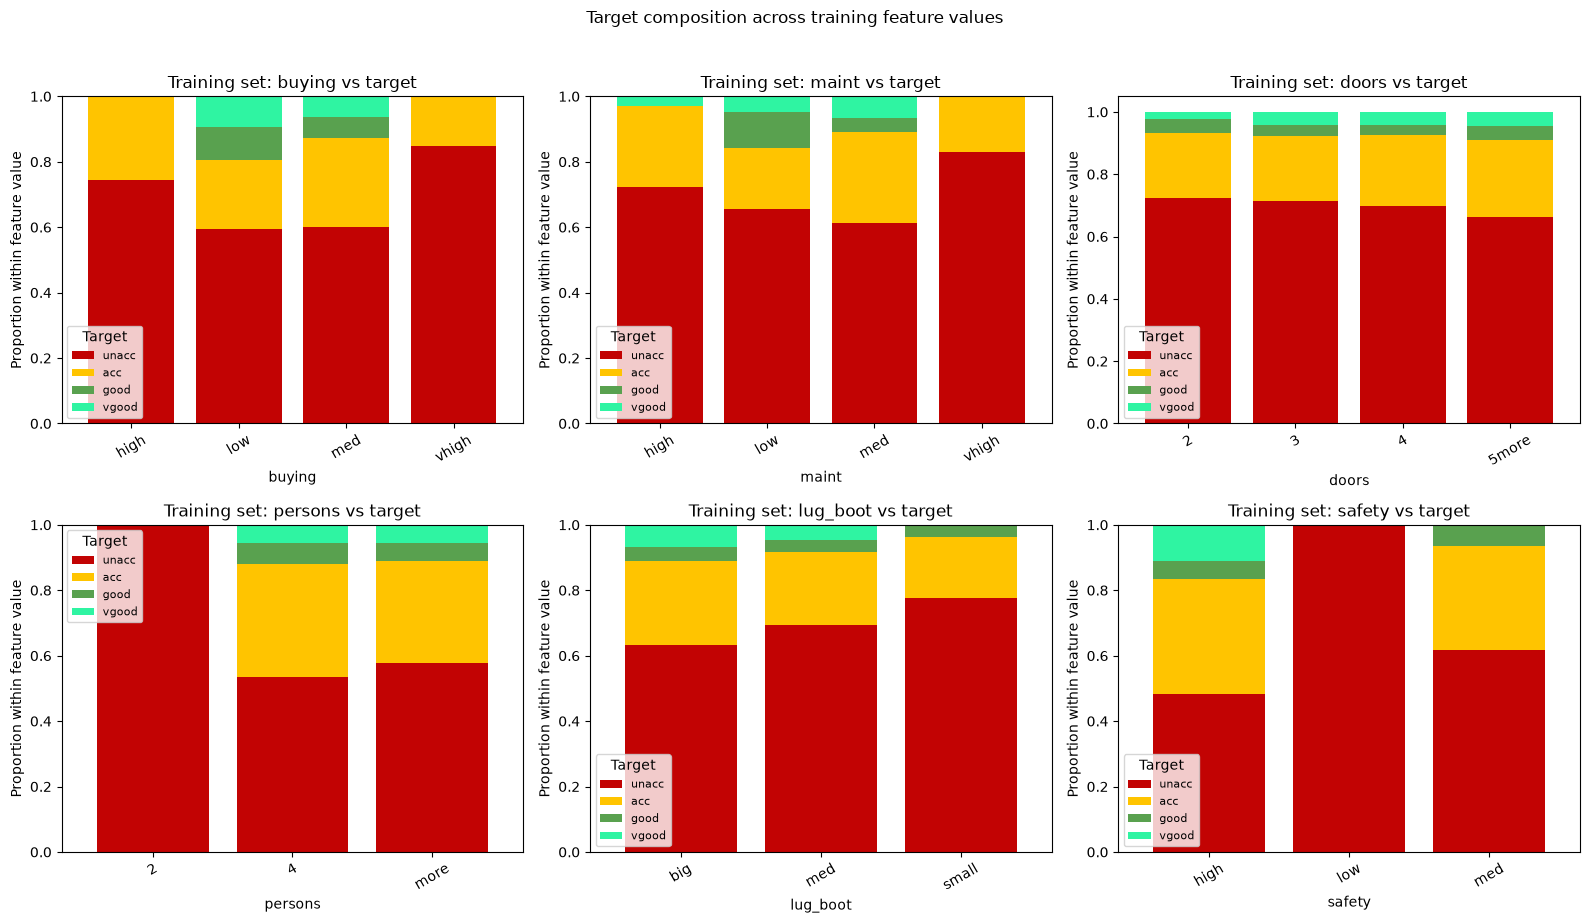

In [5]:
# Training target composition, ordered from unacc to vgood.
train_target_counts = y_train.value_counts().reindex(target_order, fill_value=0)
fig, ax = plt.subplots(figsize=(14, 2.5))
left = 0
for label in target_order:
    count = int(train_target_counts[label])
    ax.barh("Training observations", count, left=left, color=colors[label], label=f"{label} ({count})")
    left += count
ax.set_xlim(0, len(y_train))
ax.set_title("Target class composition in the training set")
ax.set_xlabel("Number of observations")
ax.legend(title="Target class", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Within each feature value, show the target proportions in the training set.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, expected_features):
    proportions = pd.crosstab(X_train[feature], y_train, normalize="index")
    proportions = proportions.reindex(columns=target_order, fill_value=0).sort_index()
    proportions.plot(kind="bar", stacked=True, ax=ax,
                     color=[colors[label] for label in target_order], width=0.8)
    ax.set_title(f"Training set: {feature} vs target")
    ax.set_xlabel(feature)
    ax.set_ylabel("Proportion within feature value")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Target", fontsize=8)
fig.suptitle("Target composition across training feature values", y=1.02)
plt.tight_layout()
plt.show()

## Model Setup, Nested CV & Hyperparameter Search

The stratified test split is held aside during model selection. Nested stratified 5-fold cross-validation runs on the training split: inner folds select hyperparameters, while outer folds estimate performance. Hyperparameters are selected by macro F1 because the target classes are imbalanced; accuracy is also reported to compare overall correctness and address the assignment brief. The CV charts below show outer-fold means with fold standard deviations.


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),
    "SVM": SVC(random_state=1),
    "Decision Tree": DecisionTreeClassifier(random_state=1),
    "MLP": MLPClassifier(max_iter=2000, random_state=1),
}

def make_categorical_pipeline(model, selector=None):
    """Apply optional feature selection, one-hot encoding, then fit a classifier."""
    steps = []
    if selector is not None:
        steps.append(selector)
    steps.extend([OneHotEncoder(handle_unknown="ignore"), model])
    return make_pipeline(*steps)

# Search spaces are intentionally compact for this categorical dataset.
parameter_grids = {
    "Logistic Regression": {
        "logisticregression__C": [0.1, 0.2, 0.5, 1.0, 5.0, 10.0],
    },
    "SVM": {
        "svc__C": [0.1, 1.0, 10.0],
        "svc__kernel": ["linear", "rbf"],
        "svc__gamma": ["scale", "auto"],
    },
    "Decision Tree": {
        "decisiontreeclassifier__max_depth": [3, 5, 10, 15],
        "decisiontreeclassifier__min_samples_leaf": [1, 2, 4],
    },
    "MLP": {
        "mlpclassifier__hidden_layer_sizes": [(50,), (100,), (100, 50)],
        "mlpclassifier__alpha": [0.0001, 0.001],
        "mlpclassifier__learning_rate_init": [0.001, 0.01],
    },
}

,Model,Nested CV macro F1,Macro F1 std,Nested CV accuracy,Accuracy std
1,SVM,0.963899,0.028917,0.987467,0.009901
3,MLP,0.962497,0.019981,0.987449,0.004932
2,Decision Tree,0.875158,0.041726,0.953670,0.007218
0,Logistic Regression,0.852042,0.022653,0.919867,0.016964


,Model,Mean training fold macro F1,Best inner CV macro F1,CV std,Best parameters
1,SVM,1.000000,0.975524,0.021360,"{'svc__C': 10.0, 'svc__gamma': 'scale', 'svc__..."
3,MLP,1.000000,0.971015,0.017532,"{'mlpclassifier__alpha': 0.0001, 'mlpclassifie..."
2,Decision Tree,1.000000,0.912880,0.034885,"{'decisiontreeclassifier__max_depth': 15, 'dec..."
0,Logistic Regression,0.899412,0.836924,0.028296,{'logisticregression__C': 10.0}


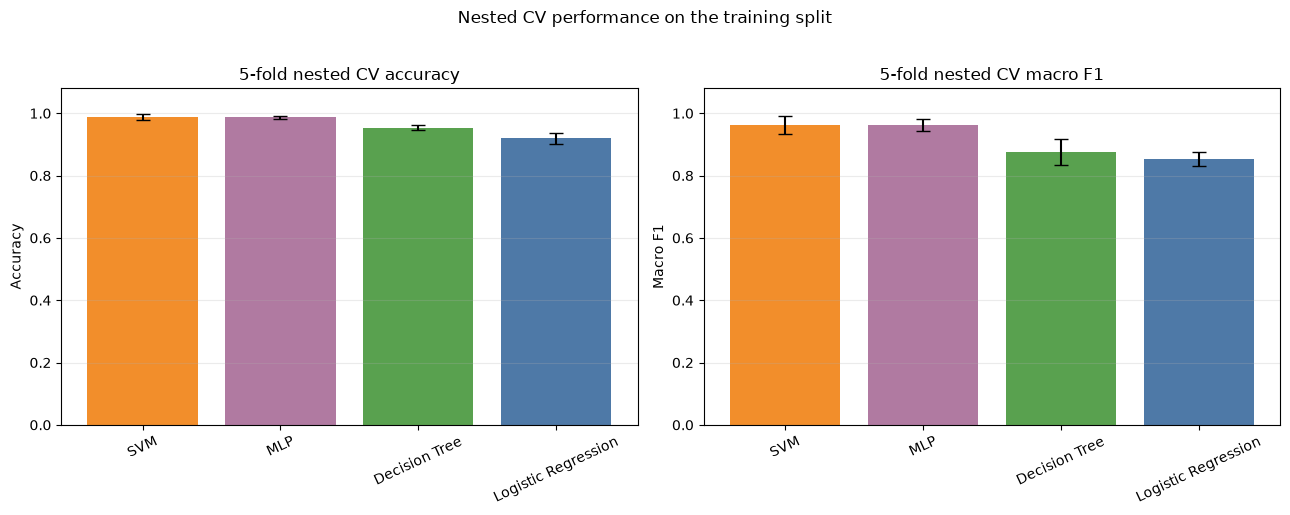

In [7]:
# Nested CV estimates the full tuning procedure using training data only.
# Outer folds estimate performance; each inner GridSearchCV selects hyperparameters.
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
scoring = {"macro_f1": "f1_macro", "accuracy": "accuracy"}
nested_results = []

for name, estimator in models.items():
    inner_search = GridSearchCV(
        estimator=make_categorical_pipeline(estimator),
        param_grid=parameter_grids[name],
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
    )
    outer_scores = cross_validate(
        inner_search,
        X_train,
        y_train,
        cv=outer_cv,
        scoring=scoring,
        n_jobs=1,  # Avoid nested parallel-job oversubscription.
        return_train_score=False,
    )
    nested_results.append({
        "Model": name,
        "Nested CV macro F1": outer_scores["test_macro_f1"].mean(),
        "Macro F1 std": outer_scores["test_macro_f1"].std(),
        "Nested CV accuracy": outer_scores["test_accuracy"].mean(),
        "Accuracy std": outer_scores["test_accuracy"].std(),
    })

nested_cv_results = pd.DataFrame(nested_results).sort_values(
    "Nested CV macro F1", ascending=False
)
display(nested_cv_results)

# After nested evaluation, tune once on all training data and refit each best pipeline.
# These final fitted estimators are the ones evaluated on the held-out test set.
search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=202)
searches = {}
search_summary = []
for name, estimator in models.items():
    search = GridSearchCV(
        estimator=make_categorical_pipeline(estimator),
        param_grid=parameter_grids[name],
        scoring="f1_macro",
        cv=search_cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train)
    searches[name] = search
    best_index = search.best_index_
    search_summary.append({
        "Model": name,
        "Mean training fold macro F1": search.cv_results_["mean_train_score"][best_index],
        "Best inner CV macro F1": search.best_score_,
        "CV std": search.cv_results_["std_test_score"][best_index],
        "Best parameters": search.best_params_,
    })

training_search_results = pd.DataFrame(search_summary).sort_values(
    "Best inner CV macro F1", ascending=False
)
display(training_search_results)
best_estimators = {name: search.best_estimator_ for name, search in searches.items()}

# Compare nested cross-validation scores from the training split.
cv_comparison = nested_cv_results.sort_values(
    "Nested CV accuracy", ascending=False
).reset_index(drop=True)
cv_models_ordered = cv_comparison["Model"]
cv_colors = {
    "Logistic Regression": "#4E79A7",
    "SVM": "#F28E2B",
    "Decision Tree": "#59A14F",
    "MLP": "#B07AA1",
}
cv_bar_colors = [cv_colors[name] for name in cv_models_ordered]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    cv_models_ordered,
    cv_comparison["Nested CV accuracy"],
    yerr=cv_comparison["Accuracy std"],
    capsize=5,
    color=cv_bar_colors,
)
axes[0].set_title("5-fold nested CV accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.08)
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    cv_models_ordered,
    cv_comparison["Nested CV macro F1"],
    yerr=cv_comparison["Macro F1 std"],
    capsize=5,
    color=cv_bar_colors,
)
axes[1].set_title("5-fold nested CV macro F1")
axes[1].set_ylabel("Macro F1")
axes[1].set_ylim(0, 1.08)
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Nested CV performance on the training split", y=1.02)
fig.tight_layout()
plt.show()


In [8]:
# Full selected hyperparameters for each final model (the table above truncates them).
for name, search in searches.items():
    print(f"{name}: {search.best_params_}")

Logistic Regression: {'logisticregression__C': 10.0}
SVM: {'svc__C': 10.0, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Decision Tree: {'decisiontreeclassifier__max_depth': 15, 'decisiontreeclassifier__min_samples_leaf': 1}
MLP: {'mlpclassifier__alpha': 0.0001, 'mlpclassifier__hidden_layer_sizes': (100, 50), 'mlpclassifier__learning_rate_init': 0.01}


## Held-out Test Set Evaluation

After cross-validation and hyperparameter selection, each selected pipeline is refitted on the full training split and evaluated once on the untouched test split. The following metrics, class-level F1 chart and SVM confusion matrix use held-out test predictions.



Logistic Regression: held-out test set
              precision    recall  f1-score   support

       unacc       0.96      0.96      0.96       484
         acc       0.84      0.86      0.85       154
        good       0.95      0.64      0.77        28
       vgood       0.81      0.96      0.88        26

    accuracy                           0.93       692
   macro avg       0.89      0.86      0.86       692
weighted avg       0.93      0.93      0.93       692


SVM: held-out test set
              precision    recall  f1-score   support

       unacc       1.00      1.00      1.00       484
         acc       0.99      1.00      0.99       154
        good       0.96      0.96      0.96        28
       vgood       1.00      0.96      0.98        26

    accuracy                           1.00       692
   macro avg       0.99      0.98      0.98       692
weighted avg       1.00      1.00      1.00       692


Decision Tree: held-out test set
              precision    recal

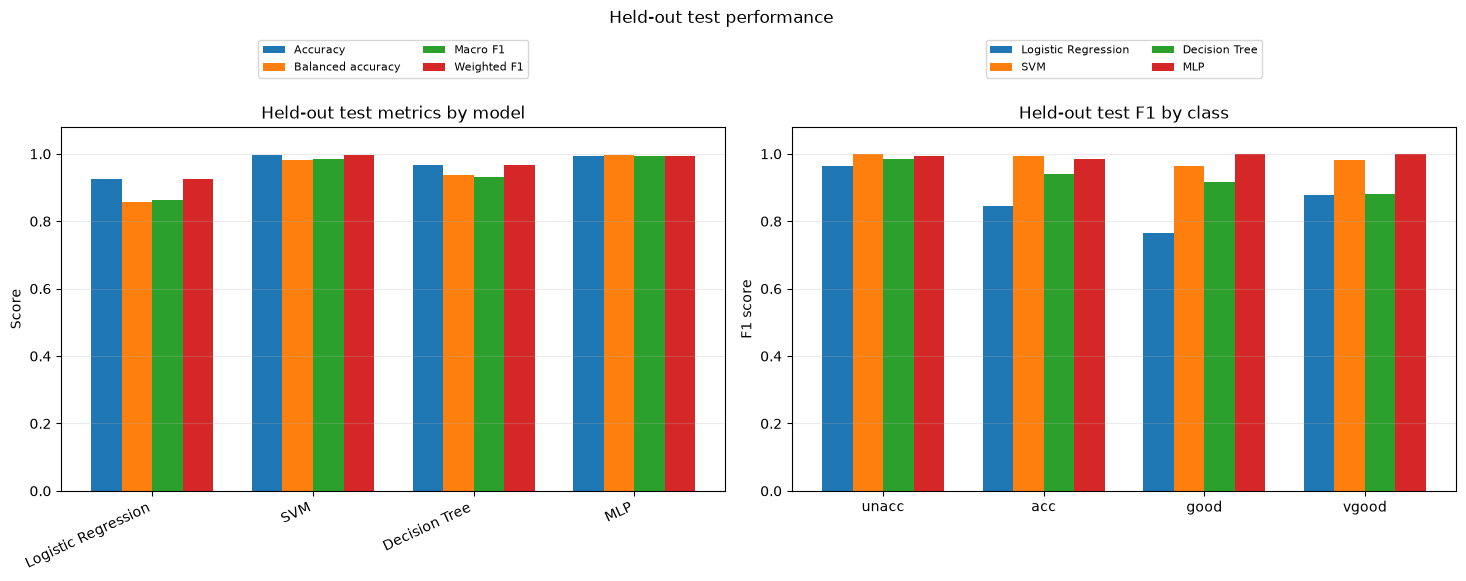

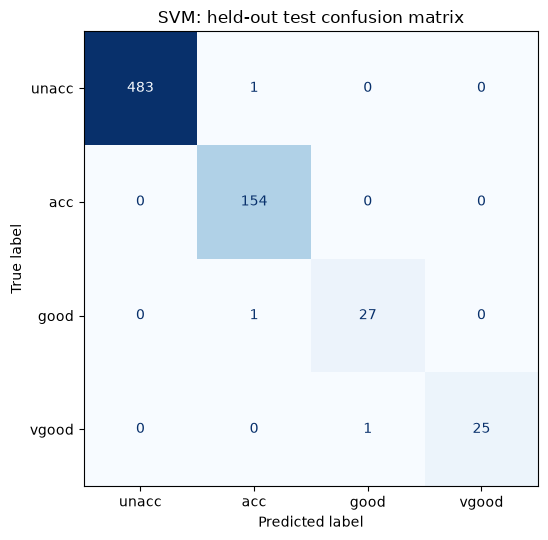

,Model,Test accuracy,Test balanced accuracy,Test macro F1,Test weighted F1
3,MLP,0.992775,0.996311,0.994685,0.992798
1,SVM,0.995665,0.980940,0.984298,0.995659
2,Decision Tree,0.968208,0.936081,0.930000,0.968375
0,Logistic Regression,0.926301,0.856087,0.863029,0.925667


,Model,Class (positive),TP,FP,TN,FN,Specificity
0,Logistic Regression,unacc,466,18,190,18,0.913462
1,Logistic Regression,acc,132,26,512,22,0.951673
2,Logistic Regression,good,18,1,663,10,0.998494
3,Logistic Regression,vgood,25,6,660,1,0.990991
4,SVM,unacc,483,0,208,1,1.000000
5,SVM,acc,154,2,536,0,0.996283
6,SVM,good,27,1,663,1,0.998494
7,SVM,vgood,25,0,666,1,1.000000
8,Decision Tree,unacc,474,4,204,10,0.980769
9,Decision Tree,acc,147,12,526,7,0.977695


In [9]:
# Evaluate each best, training-refitted pipeline on the held-out test set once.
# TP/FP/TN/FN are calculated one class vs all other classes.
test_results = []
class_count_results = []
for name, estimator in best_estimators.items():
    predictions = estimator.predict(X_test)
    test_results.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Test weighted F1": f1_score(y_test, predictions, average="weighted"),
    })

    print(f"\n{name}: held-out test set")
    print(classification_report(y_test, predictions, labels=target_order, zero_division=0))

    class_matrices = multilabel_confusion_matrix(
        y_test, predictions, labels=target_order
    )
    for label, matrix in zip(target_order, class_matrices):
        tn, fp, fn, tp = matrix.ravel()
        specificity = tn / (tn + fp) if (tn + fp) else float("nan")
        class_count_results.append({
            "Model": name,
            "Class (positive)": label,
            "TP": tp,
            "FP": fp,
            "TN": tn,
            "FN": fn,
            "Specificity": specificity,
        })

test_results_df = pd.DataFrame(test_results).sort_values(
    "Test macro F1", ascending=False
)
# Plot held-out test metrics for all four models.
test_metric_columns = {
    "Accuracy": "Test accuracy",
    "Balanced accuracy": "Test balanced accuracy",
    "Macro F1": "Test macro F1",
    "Weighted F1": "Test weighted F1",
}
model_order = list(models.keys())
x = np.arange(len(model_order))
bar_width = 0.19
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for metric_index, (metric_label, column) in enumerate(test_metric_columns.items()):
    metric_values = test_results_df.set_index("Model").loc[model_order, column]
    axes[0].bar(
        x + (metric_index - 1.5) * bar_width,
        metric_values,
        bar_width,
        label=metric_label,
    )
axes[0].set_title("Held-out test metrics by model")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.08)
axes[0].set_xticks(x, model_order, rotation=25, ha="right")
axes[0].legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.12), ncol=2)
axes[0].grid(axis="y", alpha=0.25)

# Class-level F1 highlights performance on the minority classes.
class_f1_df = pd.DataFrame(class_count_results)
class_f1_df["Class F1"] = (
    2 * class_f1_df["TP"]
    / (2 * class_f1_df["TP"] + class_f1_df["FP"] + class_f1_df["FN"])
)
class_f1_pivot = class_f1_df.pivot(
    index="Class (positive)", columns="Model", values="Class F1"
).reindex(index=target_order, columns=model_order)
class_x = np.arange(len(target_order))
class_bar_width = 0.19
for model_index, model_name in enumerate(model_order):
    axes[1].bar(
        class_x + (model_index - 1.5) * class_bar_width,
        class_f1_pivot[model_name],
        class_bar_width,
        label=model_name,
    )
axes[1].set_title("Held-out test F1 by class")
axes[1].set_ylabel("F1 score")
axes[1].set_ylim(0, 1.08)
axes[1].set_xticks(class_x, target_order)
axes[1].legend(fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.12), ncol=2)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Held-out test performance", y=0.98)
fig.subplots_adjust(left=0.06, right=0.99, bottom=0.24, top=0.80, wspace=0.10)
plt.show()

# Separate held-out test confusion matrix for the model selected by nested CV.
fig_cm, ax_cm = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_estimator(
    best_estimators["SVM"],
    X_test,
    y_test,
    labels=target_order,
    display_labels=target_order,
    values_format="d",
    cmap="Blues",
    colorbar=False,
    ax=ax_cm,
)
ax_cm.set_title("SVM: held-out test confusion matrix")
fig_cm.tight_layout()
plt.show()

display(test_results_df)

display(pd.DataFrame(class_count_results))

## Training and validation score gap

In [10]:
# Summarize the train-to-validation macro F1 gap for each selected model.
gap_results = pd.DataFrame([
    {
        "Model": name,
        "Training fold macro F1": search.cv_results_["mean_train_score"][search.best_index_],
        "Validation CV macro F1": search.best_score_,
        "Train-CV gap": (
            search.cv_results_["mean_train_score"][search.best_index_]
            - search.best_score_
        ),
    }
    for name, search in searches.items()
]).sort_values("Validation CV macro F1", ascending=False)

display(gap_results)


,Model,Training fold macro F1,Validation CV macro F1,Train-CV gap
1,SVM,1.000000,0.975524,0.024476
3,MLP,1.000000,0.971015,0.028985
2,Decision Tree,1.000000,0.912880,0.087120
0,Logistic Regression,0.899412,0.836924,0.062488


## Compare chi-square feature selection

Exploratory comparison on training data only. Feature selection is performed inside each CV fold to avoid leakage.

In [11]:
class CategoricalChiSquareSelector(BaseEstimator, TransformerMixin):
    """Select original categorical columns by chi-square association with y."""
    def __init__(self, k=4):
        self.k = k

    def fit(self, X, y):
        y_values = np.asarray(y)
        self.scores_ = np.array([
            chi2_contingency(pd.crosstab(X.iloc[:, i], y_values), correction=False)[0]
            for i in range(X.shape[1])
        ])
        self.selected_indices_ = np.argsort(self.scores_)[::-1][:self.k]
        return self

    def transform(self, X):
        return X.iloc[:, self.selected_indices_]

# Exploratory training-only comparison; selection is fitted separately in each fold.
selection_results = []
for name, model in models.items():
    settings = [("All 6 features", None)] + [
        (f"Top {k} features by chi-square", k) for k in [4, 5]
    ]
    for setting, n_selected in settings:
        selector = None if n_selected is None else CategoricalChiSquareSelector(k=n_selected)
        pipeline = make_categorical_pipeline(model, selector=selector)
        cv_scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=search_cv,
            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
            n_jobs=-1,
        )
        selection_results.append({
            "Model": name,
            "Features": setting,
            "Mean accuracy": cv_scores["test_accuracy"].mean(),
            "Accuracy std": cv_scores["test_accuracy"].std(),
            "Mean macro F1": cv_scores["test_macro_f1"].mean(),
            "Macro F1 std": cv_scores["test_macro_f1"].std(),
        })

selection_results_df = pd.DataFrame(selection_results).sort_values(["Model", "Features"])
selection_results_df

,Model,Features,Mean accuracy,Accuracy std,Mean macro F1,Macro F1 std
6,Decision Tree,All 6 features,0.964288,0.012810,0.912880,0.034885
7,Decision Tree,Top 4 features by chi-square,0.843608,0.029496,0.575114,0.036843
8,Decision Tree,Top 5 features by chi-square,0.938239,0.015017,0.841924,0.039809
0,Logistic Regression,All 6 features,0.897691,0.014718,0.728887,0.060401
1,Logistic Regression,Top 4 features by chi-square,0.859039,0.021640,0.573926,0.098822
2,Logistic Regression,Top 5 features by chi-square,0.889010,0.017719,0.721162,0.041203
9,MLP,All 6 features,0.982641,0.010355,0.947873,0.030046
10,MLP,Top 4 features by chi-square,0.842642,0.027873,0.602124,0.021501
11,MLP,Top 5 features by chi-square,0.934378,0.020570,0.840979,0.058786
3,SVM,All 6 features,0.953679,0.014481,0.836399,0.032449


## Training-set permutation importance

This is an exploratory interpretation of the selected pipelines on training data, not a held-out performance estimate.

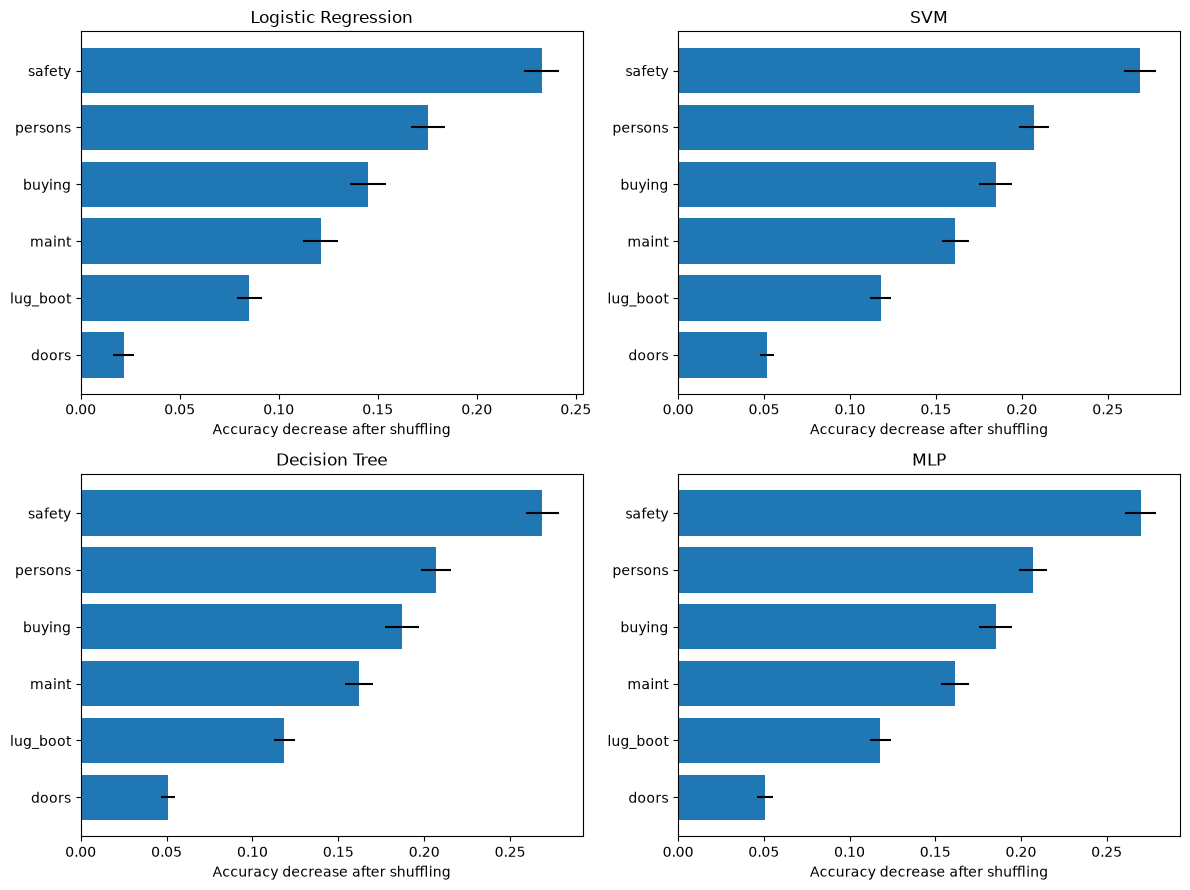

,Model,Feature,Mean accuracy decrease,Std. dev.
0,Logistic Regression,safety,0.232658,0.008678
1,Logistic Regression,persons,0.175257,0.008693
2,Logistic Regression,buying,0.144949,0.009164
3,Logistic Regression,maint,0.121075,0.008916
4,Logistic Regression,lug_boot,0.085135,0.006472
5,Logistic Regression,doors,0.021654,0.005124
6,SVM,safety,0.268887,0.009230
7,SVM,persons,0.207143,0.008574
8,SVM,buying,0.184717,0.009580
9,SVM,maint,0.161165,0.007871


In [12]:
models_for_importance = best_estimators

all_importances = []
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, pipeline) in zip(axes.flat, models_for_importance.items()):
    importance = permutation_importance(
        pipeline, X_train, y_train,
        scoring="accuracy", n_repeats=30, random_state=42, n_jobs=-1
    )

    model_importance = pd.DataFrame({
        "Model": name,
        "Feature": X.columns,
        "Mean accuracy decrease": importance.importances_mean,
        "Std. dev.": importance.importances_std,
    }).sort_values("Mean accuracy decrease", ascending=False)
    all_importances.append(model_importance)

    plot_data = model_importance.sort_values("Mean accuracy decrease")
    ax.barh(
        plot_data["Feature"], plot_data["Mean accuracy decrease"],
        xerr=plot_data["Std. dev."]
    )
    ax.set_title(name)
    ax.set_xlabel("Accuracy decrease after shuffling")

plt.tight_layout()
plt.show()

importance_df = pd.concat(all_importances, ignore_index=True)
importance_df